Saved -> e:\DATA\Python\AGB_NE\figures_main\nature_figure_combined.pdf
Saved -> e:\DATA\Python\AGB_NE\figures_main\nature_figure_combined.png


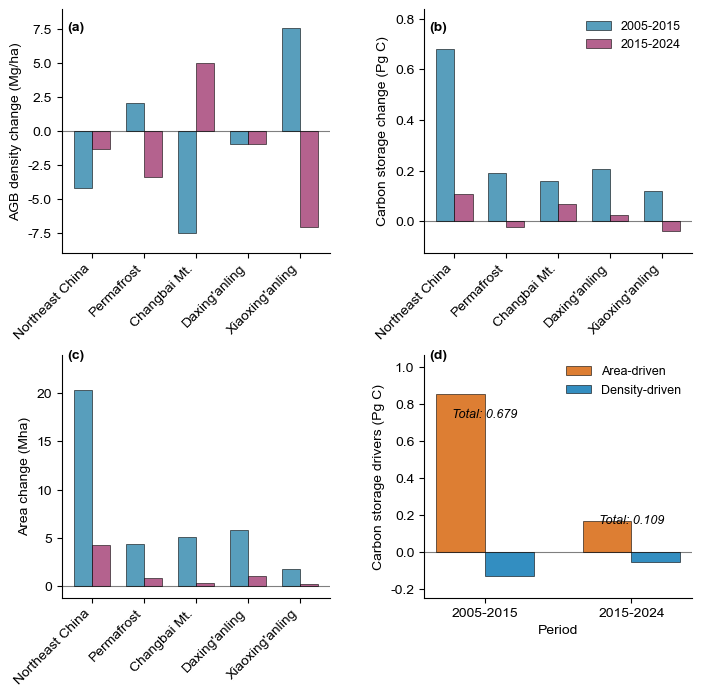


Recalculated per-region change (from RF rasters):
         Region    Period  Density_Mg_per_ha  Total_AGB_PgC  Area_Mha
Northeast China 2005-2015          -4.188660       0.678952 20.356625
     Permafrost 2005-2015           2.040471       0.190919  4.358922
   Changbai Mt. 2005-2015          -7.492995       0.157929  5.094682
  Daxing'anling 2005-2015          -0.949296       0.205322  5.838377
Xiaoxing'anling 2005-2015           7.578202       0.120771  1.740227
Northeast China 2015-2024          -1.333270       0.109214  4.200451
     Permafrost 2015-2024          -3.360876      -0.022804  0.833492
   Changbai Mt. 2015-2024           4.972740       0.069962  0.264994
  Daxing'anling 2015-2024          -0.954544       0.022907  1.046351
Xiaoxing'anling 2015-2024          -7.079197      -0.037577  0.216063

Carbon-storage decomposition (Northeast China):
   Period  AreaDriven_PgC  DensityDriven_PgC  Interaction_PgC  Total_PgC
2005-2015        0.851282          -0.129642        -0.04

In [1]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
"""
Figure 6 — Forest AGB density, carbon storage, area change, and decomposition.

AGBD, forest area, and carbon stock are RECALCULATED from the RF AGB rasters
(I:/AGB_models/regiona/RF_{2005,2015,2024} and I:/AGB_models/RF_*.tif) by
`build_fig6_tables.py`, which writes three cached CSVs next to this notebook.

Per raster (block-windowed, valid pixel = value > 0 & finite):
    forest area  = n_pixels * 0.09 ha
    AGB density  = mean Mg ha-1
    carbon stock = area_ha * density * 1e-9 * 0.5  (Pg C)

The heavy raster pass runs ONCE (build script / first run); display just
reads the cache. Set FORCE_REBUILD = True to recompute from rasters.
"""

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

plt.rcParams.update({
    'font.family': 'Arial', 'font.size': 10, 'axes.labelsize': 10,
    'axes.titlesize': 10, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 10, 'figure.titlesize': 10, 'axes.linewidth': 0.8,
    'xtick.major.width': 0.8, 'ytick.major.width': 0.8,
    'xtick.minor.width': 0.6, 'ytick.minor.width': 0.6,
    'lines.linewidth': 1.0, 'lines.markersize': 6, 'axes.unicode_minus': False,
})

# ------------------------- Cached tables -------------------------
HERE = Path(__file__).parent if "__file__" in globals() else Path.cwd()
FIGURE_TABLE_PATH = HERE / "figure6_raster_summary.csv"
DECOMP_TABLE_PATH = HERE / "figure6_decomposition_summary.csv"

FORCE_REBUILD = False  # True -> re-scan rasters via _build_fig6_tables.py (slow, do once)

REGION_ORDER = ["Northeast China", "Permafrost", "Changbai Mt.", "Daxing'anling", "Xiaoxing'anling"]
PERIODS = ["2005-2015", "2015-2024"]

COLOR_2005 = '#2E86AB'
COLOR_2015 = '#A23B72'
COLOR_AREA = '#D55E00'
COLOR_DENSITY = '#0072B2'
WIDTH = 0.35


def load_tables():
    if FORCE_REBUILD or not (FIGURE_TABLE_PATH.exists() and DECOMP_TABLE_PATH.exists()):
        import subprocess, sys
        print("Building Figure 6 tables from rasters (one-time pass)...")
        subprocess.run([sys.executable, str(HERE / "build_fig6_tables.py")], check=True)
    df = pd.read_csv(FIGURE_TABLE_PATH)
    decomp_df = pd.read_csv(DECOMP_TABLE_PATH)
    df["Region"] = pd.Categorical(df["Region"], REGION_ORDER, ordered=True)
    df["Period"] = pd.Categorical(df["Period"], PERIODS, ordered=True)
    df = df.sort_values(["Period", "Region"])
    return df, decomp_df


# ------------------------- Plot helpers -------------------------
def style_axis(ax, ylabel, xlabel="Region"):
    ax.set_xlabel(xlabel, fontweight='normal')
    ax.set_ylabel(ylabel, fontweight='normal')
    ax.tick_params(axis='both', which='major', labelsize=10)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(0.8)
    ax.axhline(0, color='black', linewidth=0.8, alpha=0.5)


def add_panel_label(ax, label, x_pos=0.02, y_pos=0.95):
    ax.text(x_pos, y_pos, label, transform=ax.transAxes, fontsize=10,
            fontweight='bold', va='top', ha='left')


def symmetric_ylim(values, pad=0.12, minimum=0.01):
    vmax = max(float(np.nanmax(np.abs(values))), minimum)
    return -vmax * (1 + pad), vmax * (1 + pad)


def skewed_ylim(values, pos_pad=0.18, neg_pad=0.06):
    vmax = float(np.nanmax(values))
    vmin = float(np.nanmin(values))
    span = vmax - vmin
    return vmin - span * neg_pad, vmax + span * pos_pad


def decomposition_lookup(decomp_df):
    return {row["Period"]: (row["AreaDriven_PgC"], row["DensityDriven_PgC"],
                            row["Interaction_PgC"], row["Total_PgC"])
            for _, row in decomp_df.iterrows()}


# ------------------------- Main figure -------------------------
def create_combined_figure(save_path=None):
    df, decomp_df = load_tables()
    decomposition = decomposition_lookup(decomp_df)

    fig = plt.figure(figsize=(180 / 25.4, 180 / 25.4))
    gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.42, wspace=0.35,
                           left=0.08, right=0.97, bottom=0.12, top=0.95)
    x = np.arange(len(REGION_ORDER))

    # (a) AGB density change
    ax_a = fig.add_subplot(gs[0, 0])
    for i, p in enumerate(PERIODS):
        sub = df[df["Period"] == p].set_index("Region").reindex(REGION_ORDER)
        color = COLOR_2005 if p == "2005-2015" else COLOR_2015
        ax_a.bar(x + (i - 0.5) * WIDTH, sub["Density_Mg_per_ha"], width=WIDTH,
                 color=color, label=p, alpha=0.8, edgecolor='black', linewidth=0.5)
    ax_a.set_ylim(*symmetric_ylim(df["Density_Mg_per_ha"].values, pad=0.18))
    ax_a.set_xticks(x)
    ax_a.set_xticklabels(REGION_ORDER, rotation=45, ha='right', fontsize=8)
    style_axis(ax_a, "AGB density change (Mg ha$^{-1}$)", xlabel="")
    add_panel_label(ax_a, "(a)")

    # (b) Carbon storage change
    ax_b = fig.add_subplot(gs[0, 1])
    for i, p in enumerate(PERIODS):
        sub = df[df["Period"] == p].set_index("Region").reindex(REGION_ORDER)
        color = COLOR_2005 if p == "2005-2015" else COLOR_2015
        ax_b.bar(x + (i - 0.5) * WIDTH, sub["Total_AGB_PgC"], width=WIDTH,
                 color=color, label=p, alpha=0.8, edgecolor='black', linewidth=0.5)
    ax_b.set_ylim(*skewed_ylim(df["Total_AGB_PgC"].values, pos_pad=0.22, neg_pad=0.12))
    ax_b.set_xticks(x)
    ax_b.set_xticklabels(REGION_ORDER, rotation=45, ha='right', fontsize=8)
    style_axis(ax_b, "Carbon storage change (Pg C)", xlabel="")
    ax_b.legend(frameon=False, loc='upper right', ncol=1, fontsize=9)
    add_panel_label(ax_b, "(b)")

    # (c) Forest area change
    ax_c = fig.add_subplot(gs[1, 0])
    for i, p in enumerate(PERIODS):
        sub = df[df["Period"] == p].set_index("Region").reindex(REGION_ORDER)
        color = COLOR_2005 if p == "2005-2015" else COLOR_2015
        ax_c.bar(x + (i - 0.5) * WIDTH, sub["Area_Mha"], width=WIDTH,
                 color=color, label=p, alpha=0.8, edgecolor='black', linewidth=0.5)
    _area_max = float(np.nanmax(df["Area_Mha"].values))
    ax_c.set_ylim(-_area_max * 0.06, _area_max * 1.18)
    ax_c.set_xticks(x)
    ax_c.set_xticklabels(REGION_ORDER, rotation=45, ha='right', fontsize=8)
    style_axis(ax_c, "Area change (Mha)", xlabel="")
    add_panel_label(ax_c, "(c)", x_pos=0.02, y_pos=1.02)

    # (d) Carbon storage decomposition (whole Northeast China)
    ax_d = fig.add_subplot(gs[1, 1])
    x_decomp = np.array([0, 1.2])
    width_decomp = 0.4
    decomp_values = []
    for idx, period in enumerate(PERIODS):
        area_c, density_c, interact_c, total_c = decomposition[period]
        decomp_values.extend([area_c, density_c, total_c])
        ax_d.bar(x_decomp[idx] - width_decomp / 2, area_c, width_decomp,
                 label='Area-driven' if idx == 0 else None, color=COLOR_AREA,
                 alpha=0.8, edgecolor='black', linewidth=0.5)
        ax_d.bar(x_decomp[idx] + width_decomp / 2, density_c, width_decomp,
                 label='Density-driven' if idx == 0 else None, color=COLOR_DENSITY,
                 alpha=0.8, edgecolor='black', linewidth=0.5)
        total_va = 'bottom' if total_c >= 0 else 'top'
        total_offset = 0.03 if total_c >= 0 else -0.03
        ax_d.text(x_decomp[idx], total_c + total_offset, f'Total: {total_c:.3f}',
                  ha='center', va=total_va, fontsize=9, style='italic')
    ax_d.set_xlim(-0.5, 1.7)
    ax_d.set_ylim(*skewed_ylim(np.array(decomp_values), pos_pad=0.22, neg_pad=0.12))
    ax_d.set_xticks(x_decomp)
    ax_d.set_xticklabels(PERIODS, fontsize=10)
    style_axis(ax_d, "Carbon storage drivers (Pg C)", xlabel="Period")
    ax_d.legend(frameon=False, loc='upper right', fontsize=9)
    add_panel_label(ax_d, "(d)", x_pos=0.02, y_pos=1.02)

    if save_path:
        save_path = str(save_path)
        Path(save_path).parent.mkdir(exist_ok=True)
        fig.savefig(save_path, dpi=600, bbox_inches='tight', format='pdf')
        fig.savefig(save_path.replace('.pdf', '.png'), dpi=600, bbox_inches='tight', format='png')
        print(f"Saved -> {save_path}")
        print(f"Saved -> {save_path.replace('.pdf', '.png')}")

    plt.show()
    return fig, df, decomp_df


fig, df, decomp_df = create_combined_figure(HERE / "output" / "Figure6_carbon_dynamics.pdf")

# Show the recalculated numbers driving the figure
print("\nRecalculated per-region change (from RF rasters):")
print(df[["Region", "Period", "Density_Mg_per_ha", "Total_AGB_PgC", "Area_Mha"]]
      .to_string(index=False))
print("\nCarbon-storage decomposition (Northeast China):")
print(decomp_df.to_string(index=False))
